# Przypisanie PS do budynków

Celem jest przygotowanie warstwy budynków, którą będzie można wykorzystać do dalszych analiz przestrzennych i wskazywania obiektów wymagających dokładniejszej obserwacji.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('.')
# Ścieżki względne: notebook uruchamiamy z katalogu repozytorium.
INPUT_PS = DATA_DIR / 'EGMS_Jastrzebie_results.csv'  # wynik notebooka EGMS_Jastrzebie_analiza_PS
INPUT_BUILDINGS = DATA_DIR / 'dane' / 'budynki_jastrzebie_done.gpkg'
OUTPUT_BUILDINGS = DATA_DIR / 'budynki_Jastrzebie_EGMS_results.gpkg'
EGMS_CRS = 'EPSG:3035'
ANALYSIS_CRS = 'EPSG:2180'
MAX_DISTANCE = 30

for file in [INPUT_PS, INPUT_BUILDINGS]:
    if not file.is_file():
        raise FileNotFoundError(f'Brakuje pliku: {file.resolve()}')

ps = pd.read_csv(INPUT_PS, dtype={'pid':'string'})
buildings = gpd.read_file(INPUT_BUILDINGS)
required = ['pid','easting','northing','mean_velocity','acceleration',
            'trend_change','anomaly_score','anomaly','cluster','rmse_ts']
missing = [c for c in required if c not in ps.columns]
if missing:
    raise ValueError(f'Brak kolumn w wynikach PS: {missing}')
if buildings.crs is None:
    raise ValueError('GPKG nie ma zdefiniowanego CRS. Sprawdź układ w QGIS.')
ps['anomaly'] = ps['anomaly'].astype('string').str.lower().eq('true').fillna(False)
ps['cluster'] = pd.to_numeric(ps['cluster'], errors='coerce').astype('Int64')
ps['easting'] = pd.to_numeric(ps['easting'], errors='coerce')
ps['northing'] = pd.to_numeric(ps['northing'], errors='coerce')
if ps[['easting','northing']].isna().any().any():
    raise ValueError('Część PS nie ma prawidłowych współrzędnych.')
print('Liczba PS:', len(ps))
print('Liczba budynków:', len(buildings))
print('CRS budynków:', buildings.crs)
print('Punkty bez przypisanego klastra:', int(ps['cluster'].isna().sum()))

Liczba PS: 3977
Liczba budynków: 26847
CRS budynków: EPSG:3035
Punkty bez przypisanego klastra: 0


## Usunięcie powtarzających się geometrii

In [2]:
# Usuwamy identyczne geometrie, ale nie ingerujemy w oryginalny plik GPKG.
buildings = buildings.loc[buildings.geometry.notna() & ~buildings.geometry.is_empty].copy()
buildings = buildings.drop_duplicates(subset='geometry').reset_index(drop=True)
buildings['building_id'] = np.arange(1, len(buildings)+1)
print('Liczba budynków bez identycznych duplikatów:', len(buildings))

Liczba budynków bez identycznych duplikatów: 26847


## Ujednolicenie układów współrzędnych

In [3]:
ps_gdf = gpd.GeoDataFrame(
    ps.copy(), geometry=gpd.points_from_xy(ps['easting'], ps['northing']), crs=EGMS_CRS
).to_crs(ANALYSIS_CRS)
buildings = buildings.to_crs(ANALYSIS_CRS)
print('CRS PS po transformacji:',ps_gdf.crs)
print('CRS budynków po transformacji:', buildings.crs)
print('Zakres PS:',tuple(round(x) for x in ps_gdf.total_bounds))
print('Zakres budynków:',tuple(round(x) for x in buildings.total_bounds))
# Jeśli zakresy nie pokrywają się, sprawdź wejściowy EPSG i poprawność współrzędnych.

CRS PS po transformacji:

 EPSG:2180
CRS budynków po transformacji: EPSG:2180
Zakres PS: (467895, 227798, 481319, 237736)
Zakres budynków: (467882, 227798, 481649, 237780)


## Wybór geometrii i atrybutów

In [4]:
building_footprints = buildings[
    ["building_id", "geometry"]
].copy()

print("Typy geometrii:")
print(building_footprints.geometry.geom_type.value_counts())

Typy geometrii:
MultiPolygon    26847
Name: count, dtype: int64


In [5]:
ps_for_join = ps_gdf[
    [
        "pid",
        "mean_velocity",
        "acceleration",
        "trend_change",
        "anomaly_score",
        "anomaly",
        "cluster",
        "rmse_ts",
        "geometry"
    ]
].copy()

## Przypisanie najbliższego PS


In [6]:
# Odległość do punktu liczona od POLIGONU budynku, nie od jego centroidu.
buildings_ps_all = gpd.sjoin_nearest(
    building_footprints,
    ps_for_join,
    how='left',
    max_distance=MAX_DISTANCE,
    distance_col='distance_PS'
)

In [7]:
buildings_ps = (
    buildings_ps_all
    .reset_index(drop=True)
    .sort_values(['building_id','distance_PS','anomaly_score'],
                 ascending=[True,True,False], na_position='last')
    .drop_duplicates(subset='building_id',keep='first')
    .reset_index(drop=True)
)
buildings_ps['has_PS'] = buildings_ps['pid'].notna()
buildings_ps['anomaly_assigned'] = buildings_ps['anomaly'].fillna(False).astype(bool)

In [8]:
matched = buildings_ps['has_PS']
print('Wszystkie budynki:',len(buildings_ps))
print(f'Budynki z najbliższym PS w odległości do {MAX_DISTANCE} m:',int(matched.sum()))
print('Budynki bez przypisanego PS:',int((~matched).sum()))
print('Odsetek budynków przypisanych:',round(100*matched.mean(),1),'%')
print('Budynki przypisane do anomalnego PS:',int(buildings_ps['anomaly_assigned'].sum()))
print('Wykorzystane unikalne PS:',buildings_ps['pid'].nunique())
print('PS wewnątrz obrysu budynku:',int((buildings_ps['distance_PS']==0).sum()))
print('Mediana odległości [m]:',round(buildings_ps.loc[matched,'distance_PS'].median(),1))
print('Liczebność budynków wg klastrów:')
print(buildings_ps.groupby('cluster',dropna=False).size())

Wszystkie budynki: 26847
Budynki z najbliższym PS w odległości do 30 m: 9161
Budynki bez przypisanego PS: 17686
Odsetek budynków przypisanych: 34.1 %
Budynki przypisane do anomalnego PS: 400
Wykorzystane unikalne PS: 2806
PS wewnątrz obrysu budynku: 280
Mediana odległości [m]: 18.8
Liczebność budynków wg klastrów:
cluster
0        8129
1        1032
<NA>    17686
dtype: int64


**Komentarz.** PS przypisano do 9161 z 26 847 budynków (34,1%). Niski odsetek wynika z rozdzielczości EGMS Ortho: punkty leżą w siatce co 100 m, więc jeden PS przypada na ok. 1 ha terenu i większość budynków nie ma punktu bliżej niż 30 m. Ten sam PS często opisuje kilka sąsiednich budynków (2806 unikalnych PS na 9161 budynków). Wynik należy więc czytać jako informację o ruchu terenu w otoczeniu budynku, a nie o deformacji konkretnego obiektu.

## Utworzenie warstwy wynikowej

In [9]:
result = buildings.merge(
    buildings_ps.drop(columns=['geometry','index_right'],errors='ignore'),
    on='building_id',how='left'
)
result = gpd.GeoDataFrame(result,geometry='geometry',crs=buildings.crs)
result['anomaly_assigned'] = result['anomaly_assigned'].fillna(False).astype(bool)
result['has_PS'] = result['has_PS'].fillna(False).astype(bool)
print('Budynki w wyniku:',len(result))
print('Budynki z przypisanym PS:',int(result['has_PS'].sum()))
print('Budynki z anomalnym przypisanym PS:',int(result['anomaly_assigned'].sum()))
print('Unikalne identyfikatory budynków:',result['building_id'].nunique())

Budynki w wyniku: 26847
Budynki z przypisanym PS: 9161
Budynki z anomalnym przypisanym PS: 400
Unikalne identyfikatory budynków: 26847


In [10]:
# Usuń wyłącznie poprzednią WYNIKOWĄ wersję GPKG, by zapis nie dopisywał warstw.
if OUTPUT_BUILDINGS.exists():
    OUTPUT_BUILDINGS.unlink()
result.to_file(OUTPUT_BUILDINGS,layer='budynki_EGMS',driver='GPKG')
print('Zapisano:',OUTPUT_BUILDINGS.resolve())
print('W QGIS: kolor wg cluster; czerwony obrys jeśli anomaly_assigned = True;')
print('szary dla has_PS = False / pustego cluster.')

Zapisano: C:\Users\hubi7\Desktop\Uczelnia\Analiza i przetwarzanie danych przestrzennych\jz\budynki_Jastrzebie_EGMS_results.gpkg
W QGIS: kolor wg cluster; czerwony obrys jeśli anomaly_assigned = True;
szary dla has_PS = False / pustego cluster.


## Mapa budynków według klastrów

Budynki kolorujemy według klastra przypisanego PS, a budynki z anomalnym PS wyróżniamy czerwonym obrysem i okręgiem (w skali całego obszaru pojedyncze budynki są bardzo małe). Mapa jest zapisywana w `rysunki/mapa_budynki_klastry_anomalie.png`; wersja z podkładem OSM została przygotowana w QGIS (`warstwy.gpkg`).

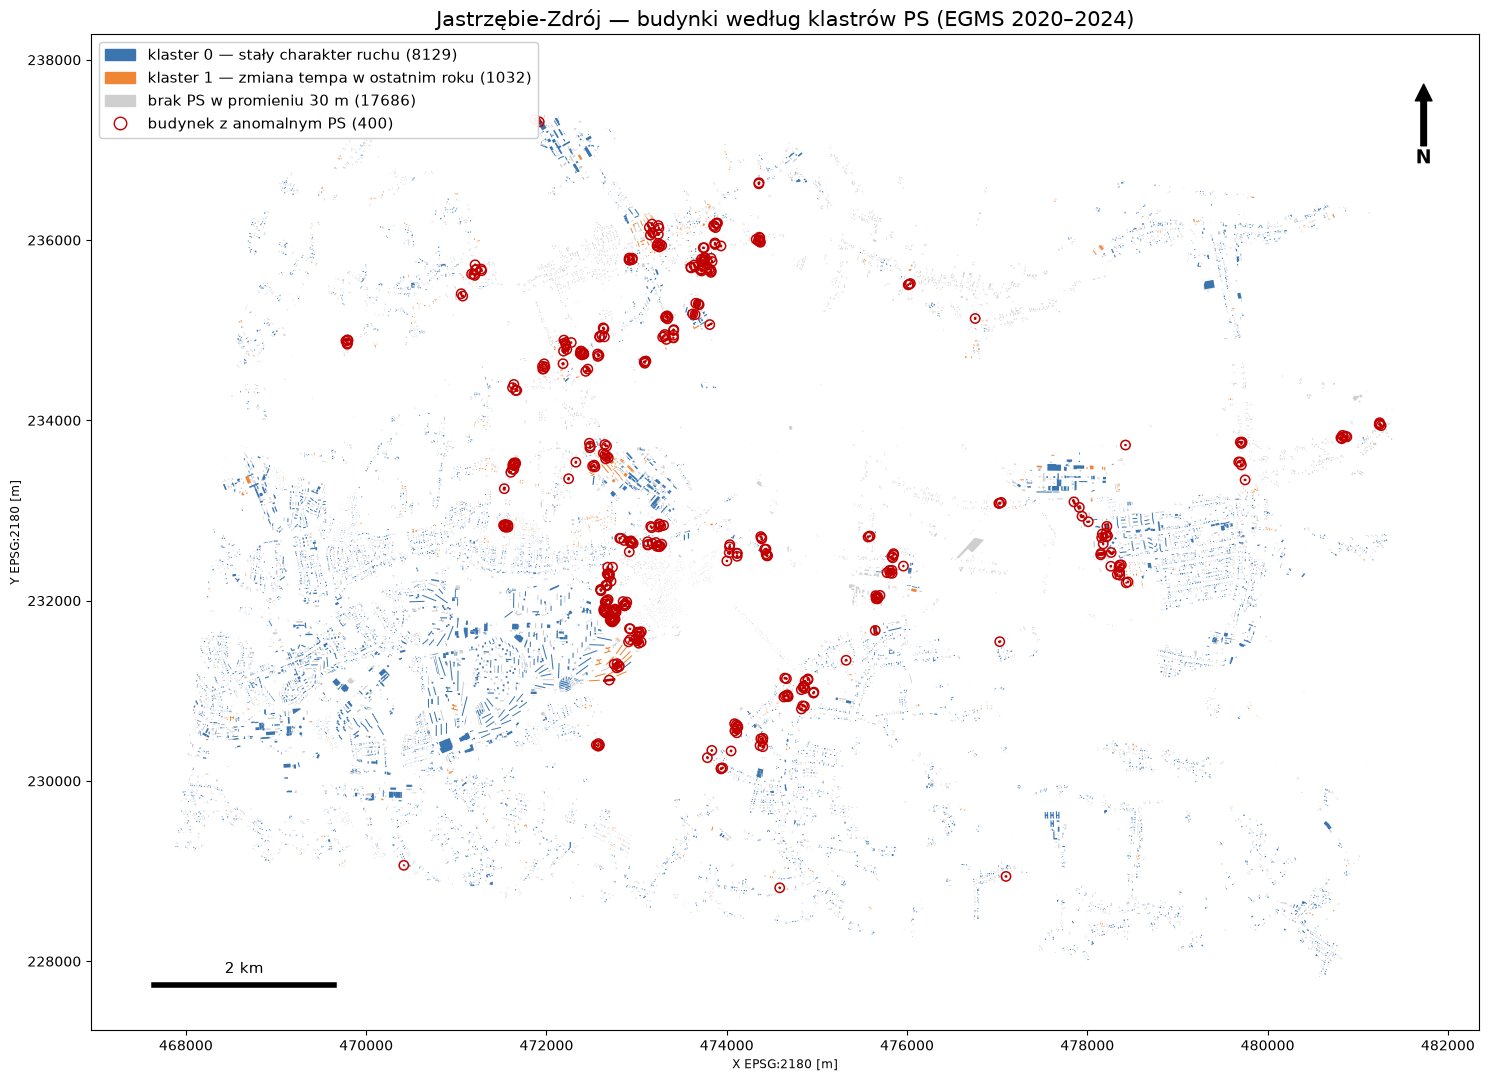

In [11]:
# Mapa końcowa: budynki według klastra przypisanego PS, budynki z anomalnym PS wyróżnione na czerwono.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

FIG_DIR = DATA_DIR / 'rysunki'
FIG_DIR.mkdir(exist_ok=True)

is_cl0 = result['cluster'].eq(0).fillna(False).astype(bool)
is_cl1 = result['cluster'].eq(1).fillna(False).astype(bool)
anom_b = result.loc[result['anomaly_assigned']]

fig, ax = plt.subplots(figsize=(15, 11))
result.loc[~result['has_PS']].plot(ax=ax, color='#cfcfcf', linewidth=0)
result.loc[is_cl0].plot(ax=ax, color='#3b75af', linewidth=0)
result.loc[is_cl1].plot(ax=ax, color='#ef8636', linewidth=0)
anom_b.plot(ax=ax, facecolor='none', edgecolor='#c00000', linewidth=1.2)
# W skali miasta pojedyncze budynki są małe, dlatego budynki z anomalnym PS zaznaczamy też okręgiem.
ax.scatter(anom_b.centroid.x, anom_b.centroid.y, s=45, facecolors='none',
           edgecolors='#c00000', linewidths=1.1)

# Podziałka 2 km i strzałka północy
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
sx, sy = x0 + 0.03 * (x1 - x0), y0 + 0.04 * (y1 - y0)
ax.plot([sx, sx + 2000], [sy, sy], color='black', linewidth=4)
ax.text(sx + 1000, sy + 0.012 * (y1 - y0), '2 km', ha='center', fontsize=11)
ax.annotate('N', xy=(x1 - 0.04 * (x1 - x0), y1 - 0.05 * (y1 - y0)),
            xytext=(x1 - 0.04 * (x1 - x0), y1 - 0.13 * (y1 - y0)),
            ha='center', fontsize=14, fontweight='bold',
            arrowprops=dict(facecolor='black', width=4, headwidth=12))

n_no_ps = int((~result['has_PS']).sum())
legend_items = [
    Patch(color='#3b75af', label=f'klaster 0 — stały charakter ruchu ({int(is_cl0.sum())})'),
    Patch(color='#ef8636', label=f'klaster 1 — zmiana tempa w ostatnim roku ({int(is_cl1.sum())})'),
    Patch(color='#cfcfcf', label=f'brak PS w promieniu {MAX_DISTANCE} m ({n_no_ps})'),
    Line2D([], [], marker='o', linestyle='none', markerfacecolor='none', markeredgecolor='#c00000',
           markersize=9, label=f'budynek z anomalnym PS ({len(anom_b)})'),
]
ax.legend(handles=legend_items, loc='upper left', fontsize=11, framealpha=0.95)
ax.set_title('Jastrzębie-Zdrój — budynki według klastrów PS (EGMS 2020–2024)', fontsize=15)
ax.set_xlabel('X EPSG:2180 [m]')
ax.set_ylabel('Y EPSG:2180 [m]')
ax.ticklabel_format(style='plain')
plt.tight_layout()
plt.savefig(FIG_DIR / 'mapa_budynki_klastry_anomalie.png', dpi=200, bbox_inches='tight')
plt.show()

## Budynki wskazane do dalszej analizy

Najpewniejsze są anomalie, które nie występują pojedynczo, tylko tworzą skupiska (pojedynczy anomalny PS może być błędem albo efektem lokalnym). Wyznaczamy skupiska anomalii tak samo jak w notebooku PS (anomalne PS oddalone o ≤ 150 m) i dla każdego budynku z anomalnym PS zapisujemy numer skupiska i jego wielkość.

In [12]:
from sklearn.cluster import DBSCAN

# Skupiska anomalii wyznaczamy tak samo jak w notebooku PS:
# anomalne PS oddalone o <= 150 m tworzą jedną grupę, numeracja od największej.
anom_ps = ps.loc[ps['anomaly']].copy()
anom_ps['anomaly_group'] = DBSCAN(eps=150, min_samples=1).fit_predict(anom_ps[['easting', 'northing']])
group_size = (
    anom_ps.groupby('anomaly_group').size().rename('n_PS_w_skupisku').reset_index()
    .sort_values(['n_PS_w_skupisku', 'anomaly_group'], ascending=[False, True])
)
group_size['nr_skupiska'] = np.arange(1, len(group_size) + 1)
anom_ps = anom_ps.merge(group_size, on='anomaly_group')

to_check = result.loc[result['anomaly_assigned']].merge(
    anom_ps[['pid', 'nr_skupiska', 'n_PS_w_skupisku']], on='pid', how='left')
to_check['w_skupisku'] = to_check['n_PS_w_skupisku'] >= 5

print('Budynki z anomalnym PS:', len(to_check))
print('  w skupiskach >= 5 anomalii:', int(to_check['w_skupisku'].sum()))
print('  przy pojedynczych anomaliach:', int((to_check['n_PS_w_skupisku'] == 1).sum()))
print('  mieszkalne:', int((to_check['type'] == 'residential').sum()))

summary = (
    to_check.loc[to_check['w_skupisku']]
    .groupby('nr_skupiska')
    .agg(n_budynkow=('building_id', 'count'),
         n_mieszkalnych=('type', lambda s: int((s == 'residential').sum())),
         median_velocity=('mean_velocity', 'median'),
         median_trend_change=('trend_change', 'median'),
         max_anomaly_score=('anomaly_score', 'max'))
    .round(2)
)

centroids = to_check.geometry.centroid
cols = ['building_id', 'type', 'pid', 'distance_PS', 'cluster', 'mean_velocity',
        'trend_change', 'anomaly_score', 'nr_skupiska', 'n_PS_w_skupisku', 'w_skupisku']
(to_check[cols]
 .assign(x_2180=centroids.x.round(1), y_2180=centroids.y.round(1))
 .sort_values(['w_skupisku', 'n_PS_w_skupisku', 'anomaly_score'], ascending=False)
 .to_csv(DATA_DIR / 'budynki_do_dalszej_analizy.csv', index=False))
print('Zapisano listę budynków: budynki_do_dalszej_analizy.csv')
summary

Budynki z anomalnym PS: 400
  w skupiskach >= 5 anomalii: 173
  przy pojedynczych anomaliach: 91
  mieszkalne: 172
Zapisano listę budynków: budynki_do_dalszej_analizy.csv


,n_budynkow,n_mieszkalnych,median_velocity,median_trend_change,max_anomaly_score
nr_skupiska,,,,,
1,51,22,20.80,-6.00,0.73
2,20,4,-20.10,13.23,0.71
3,28,17,23.20,-1.78,0.71
4,20,5,-22.80,-4.75,0.72
5,7,3,24.60,1.39,0.68
6,14,3,9.10,13.76,0.70
7,4,0,-16.75,-6.24,0.69
8,10,4,14.60,-15.32,0.71
9,6,0,12.70,-13.29,0.70


### Wnioski — budynki

- 400 budynków (1,5% wszystkich, 4,4% budynków z przypisanym PS) ma przypisany anomalny PS; 172 z nich to budynki mieszkalne.
- 173 z tych budynków leżą w 10 skupiskach liczących co najmniej 5 anomalnych PS, a 91 — przy pojedynczych anomaliach (te są mniej pewne).
- Najwięcej budynków do sprawdzenia jest w skupisku 1 (51 budynków, w tym 22 mieszkalne; wschodni skraj zwartej zabudowy centrum, ruch ok. +21 mm/rok) i w skupisku 3 (28 budynków, w tym 17 mieszkalnych; północna część obszaru, ok. +23 mm/rok). W skupiskach 2 i 4 jest po 20 budynków — skupisko 2 to ruch na zachód, który wyraźnie zmienił tempo w 2024 r., a skupisko 4 (zachodni skraj Pawłowic) to najszybszy ruch na zachód (ok. −23 mm/rok).
- Ponieważ PS leżą w siatce 100 m, wynik nie mówi o uszkodzeniu konkretnego budynku, tylko wskazuje budynki w otoczeniu nietypowego ruchu terenu. Kolejnym krokiem powinno być porównanie z mapą terenów górniczych, pomiarami geodezyjnymi albo oględzinami budynków.
- Pełna lista (najpierw budynki w największych skupiskach): `budynki_do_dalszej_analizy.csv`.